# پروژه تحلیل اکتشافی داده‌ها (EDA): Airbnb Open Data
## دفترچه ۲ — توزیع‌ها، نمودارها، روابط و آزمون‌های آماری

این دفترچه بر اساس خروجی دفترچه اول ساخته شده است. هدف، پاسخ دادن به پرسش‌های تحقیق با آمار توصیفی، نمودار و آزمون‌های آماری است. هر آزمون باید با فرضیه روشن، نمونه مورد استفاده و تفسیر محدودیت‌ها همراه باشد.

**نکته:** همبستگی به‌تنهایی علیت را ثابت نمی‌کند؛ همچنین این دیتاست مشاهده‌ای است و نتایج را نباید به‌عنوان رابطه علت و معلولی تفسیر کرد.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

DATA_PATH = Path("../data/airbnb_cleaned.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/airbnb_cleaned.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("ابتدا نوت‌بوک 01 را اجرا کنید تا airbnb_cleaned.csv ساخته شود.")

df = pd.read_csv(DATA_PATH, low_memory=False)
if "last review" in df.columns:
    df["last review"] = pd.to_datetime(df["last review"], errors="coerce")
print(f"تعداد ردیف‌ها: {len(df):,}")
print(f"تعداد ستون‌ها: {df.shape[1]}")
display(df.head())

تعداد ردیف‌ها: 102,058
تعداد ستون‌ها: 27


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,country code,instant_bookable,cancellation_policy,room type,Construction year,price,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license,price_outlier_iqr
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,US,False,strict,Private room,2020.0,966.0,193.0,10.0,9.0,2021-10-19,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN,False
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,US,False,moderate,Entire home/apt,2007.0,142.0,28.0,30.0,45.0,2022-05-21,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN,False
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,US,True,flexible,Private room,2005.0,620.0,124.0,3.0,0.0,NaT,0.00,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN,False
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,US,True,moderate,Entire home/apt,2005.0,368.0,74.0,30.0,270.0,2019-07-05,4.64,4.0,1.0,322.0,NaN,NaN,False
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,US,False,moderate,Entire home/apt,2009.0,204.0,41.0,10.0,9.0,2018-11-19,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN,False


## ۱. تعریف متغیرهای تحلیل و آمار توصیفی

در تحلیل قیمت فقط آگهی‌هایی وارد می‌شوند که قیمت عددی و معتبر دارند. داده پرت‌ها در این مرحله به‌صورت پیش‌فرض حذف نمی‌شوند؛ چون قیمت‌های بالاتر ممکن است واقعی باشند. علاوه بر میانگین، میانه و چارک‌ها را گزارش می‌کنیم، زیرا میانگین به مقادیر بسیار بزرگ حساس است.

In [2]:
price_df = df.loc[df["price"].notna() & (df["price"] > 0)].copy()
numeric_candidates = [
    "price", "service fee", "minimum nights", "number of reviews",
    "reviews per month", "review rate number", "calculated host listings count",
    "availability 365", "Construction year", "lat", "long"
]
numeric_cols = [c for c in numeric_candidates if c in df.columns]
display(price_df["price"].describe(percentiles=[.01, .25, .5, .75, .9, .95, .99]).to_frame("price_statistics"))

summary = price_df[numeric_cols].describe().T
summary["median"] = price_df[numeric_cols].median(numeric_only=True)
summary["skewness"] = price_df[numeric_cols].skew(numeric_only=True)
summary["kurtosis"] = price_df[numeric_cols].kurtosis(numeric_only=True)
display(summary)
print(f"تعداد آگهی‌های دارای قیمت معتبر: {len(price_df):,}")

,price_statistics
count,101811.000000
mean,625.355580
std,331.672649
min,50.000000
1%,61.000000
25%,340.000000
50%,625.000000
75%,913.000000
90%,1086.000000
95%,1143.000000


,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis
price,101811.0,625.355580,331.672649,50.00000,340.000000,625.00000,913.00000,1200.00000,625.00000,0.001072,-1.194201
service fee,101572.0,125.050811,66.333719,10.00000,68.000000,125.00000,183.00000,240.00000,125.00000,0.001518,-1.193896
minimum nights,101398.0,8.136867,30.343706,1.00000,2.000000,3.00000,5.00000,5645.00000,3.00000,89.867102,14084.252440
number of reviews,101628.0,27.522189,49.584331,0.00000,1.000000,7.00000,31.00000,1024.00000,7.00000,3.840132,25.031870
reviews per month,101667.0,1.164619,1.683798,0.00000,0.090000,0.48000,1.71000,90.00000,0.48000,6.973968,217.495564
review rate number,101492.0,3.278909,1.284891,1.00000,2.000000,3.00000,4.00000,5.00000,3.00000,-0.138807,-1.127009
calculated host listings count,101492.0,7.927482,32.258884,1.00000,1.000000,1.00000,2.00000,332.00000,1.00000,7.229059,58.753111
availability 365,98190.0,134.526164,129.802316,0.00000,2.000000,90.00000,254.00000,365.00000,90.00000,0.493605,-1.255980
Construction year,101601.0,2012.487663,5.765345,2003.00000,2007.000000,2012.00000,2017.00000,2022.00000,2012.00000,0.005831,-1.207004
lat,101803.0,40.728094,0.055866,40.49979,40.688715,40.72228,40.76277,40.91697,40.72228,0.230868,0.146318


تعداد آگهی‌های دارای قیمت معتبر: 101,811


### تفسیر آمار توصیفی
- اختلاف زیاد میانگین و میانه معمولاً نشانه چولگی یا اثر مقادیر دورافتاده است.
- انحراف معیار میزان پراکندگی حول میانگین را نشان می‌دهد و به مقادیر پرت حساس است.
- IQR برابر فاصله چارک سوم و اول است و برای توصیف پراکندگی مقاوم‌تر از انحراف معیار است.
- چولگی مثبت یعنی دنباله توزیع به سمت مقادیر بزرگ‌تر کشیده شده است؛ کشیدگی بالا نیز می‌تواند نشان‌دهنده دنباله‌های سنگین‌تر باشد.

## ۲. توزیع قیمت و تبدیل لگاریتمی

ValueError: Invalid RGBA argument: None

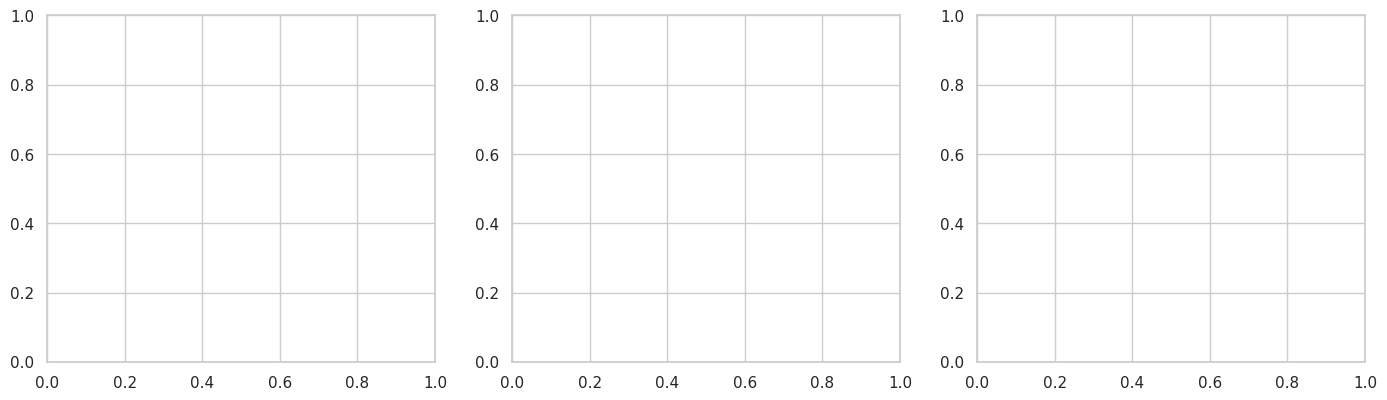

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(price_df["price"], bins=45, kde=True, ax=axes[0])
axes[0].set_title("توزیع قیمت خام")
axes[0].set_xlabel("قیمت")
sns.boxplot(x=price_df["price"], ax=axes[1])
axes[1].set_title("Boxplot قیمت خام")
axes[1].set_xlabel("قیمت")
sns.histplot(np.log1p(price_df["price"]), bins=45, kde=True, ax=axes[2])
axes[2].set_title("توزیع log(1 + price)")
axes[2].set_xlabel("log(1 + price)")
plt.tight_layout()
plt.show()

price_skew = price_df["price"].skew()
print(f"چولگی قیمت خام: {price_skew:.3f}")
print(f"چولگی قیمت پس از log1p: {np.log1p(price_df['price']).skew():.3f}")

تبدیل لگاریتمی می‌تواند دامنه مقادیر بزرگ را فشرده کند و شکل توزیع را متقارن‌تر کند؛ اما قیمت لگاریتمی دیگر واحد دلار ندارد. در نتیجه، قیمت خام برای تفسیر تجاری و قیمت لگاریتمی برای بعضی تحلیل‌های آماری یا مدل‌سازی مناسب‌تر است.

## ۳. فراوانی و مقایسه متغیرهای دسته‌ای


فراوانی ستون: room type


,count
room type,
Entire home/apt,53429
Private room,46306
Shared room,2208
Hotel room,115



فراوانی ستون: neighbourhood group


,count
neighbourhood group,
Manhattan,43558
Brooklyn,41631
Queens,13197
Bronx,2694
Staten Island,949
NaN,29



فراوانی ستون: cancellation_policy


,count
cancellation_policy,
moderate,34162
strict,33929
flexible,33891
NaN,76



فراوانی ستون: host_identity_verified


,count
host_identity_verified,
unconfirmed,50944
verified,50825
NaN,289



فراوانی ستون: instant_bookable


,count
instant_bookable,
False,51186
True,50767
NaN,105


ValueError: Invalid RGBA argument: None

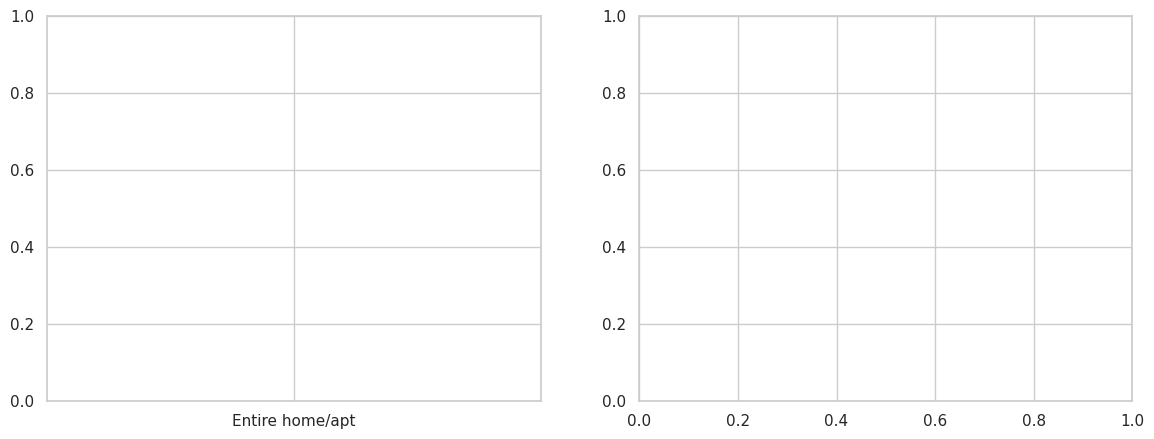

In [4]:
for col in ["room type", "neighbourhood group", "cancellation_policy", "host_identity_verified", "instant_bookable"]:
    if col in df.columns:
        print(f"\nفراوانی ستون: {col}")
        display(df[col].value_counts(dropna=False).head(15).to_frame("count"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
room_counts = df["room type"].value_counts(dropna=False)
sns.barplot(x=room_counts.index.astype(str), y=room_counts.values, ax=axes[0])
axes[0].set_title("تعداد آگهی بر اساس نوع اتاق")
axes[0].set_xlabel("نوع اتاق")
axes[0].set_ylabel("تعداد")
axes[0].tick_params(axis="x", rotation=25)

if "neighbourhood group" in df.columns:
    borough_counts = df["neighbourhood group"].value_counts(dropna=False)
    sns.barplot(x=borough_counts.index.astype(str), y=borough_counts.values, ax=axes[1])
    axes[1].set_title("تعداد آگهی بر اساس منطقه")
    axes[1].set_xlabel("منطقه")
    axes[1].set_ylabel("تعداد")
    axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## ۴. مقایسه قیمت بر اساس نوع اتاق و منطقه

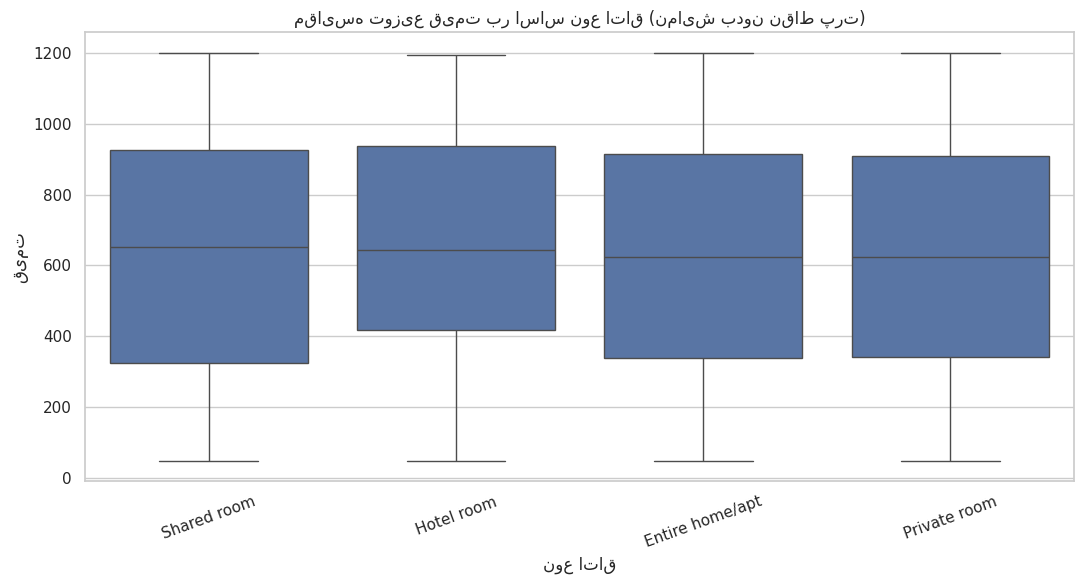

,count,mean,median,std
room type,,,,
Shared room,2200,634.83,651.5,338.41
Hotel room,115,666.39,643.0,311.42
Entire home/apt,53296,625.24,624.0,331.70
Private room,46200,624.94,623.0,331.36


,count,mean,median,std
neighbourhood group,,,,
Bronx,2687,627.76,632.0,323.81
Staten Island,946,623.99,628.0,325.78
Queens,13164,630.22,628.0,334.15
Brooklyn,41538,626.50,626.0,331.94
Manhattan,43448,622.65,621.0,331.26


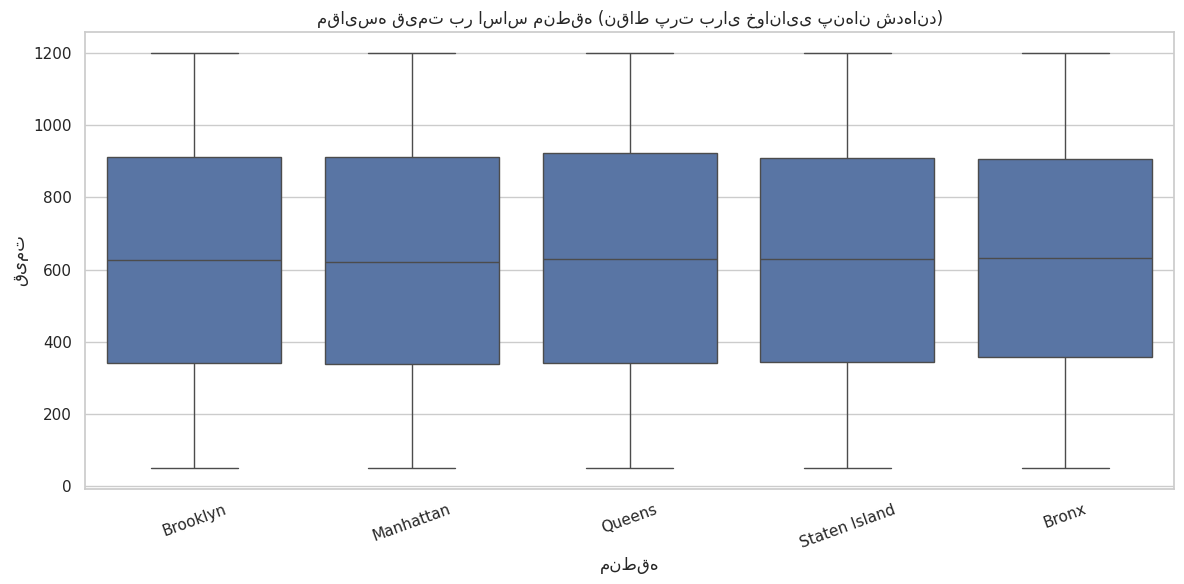

In [5]:
room_order = price_df.groupby("room type")["price"].median().sort_values(ascending=False).index
plt.figure(figsize=(11, 6))
sns.boxplot(data=price_df, x="room type", y="price", order=room_order, showfliers=False)
plt.title("مقایسه توزیع قیمت بر اساس نوع اتاق (نمایش بدون نقاط پرت)")
plt.xlabel("نوع اتاق")
plt.ylabel("قیمت")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

room_summary = price_df.groupby("room type")["price"].agg(
    count="count", mean="mean", median="median", std="std"
).sort_values("median", ascending=False)
display(room_summary.round(2))

if "neighbourhood group" in price_df.columns:
    borough_summary = price_df.groupby("neighbourhood group")["price"].agg(
        count="count", mean="mean", median="median", std="std"
    ).sort_values("median", ascending=False)
    display(borough_summary.round(2))
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=price_df, x="neighbourhood group", y="price", showfliers=False)
    plt.title("مقایسه قیمت بر اساس منطقه (نقاط پرت برای خوانایی پنهان شده‌اند)")
    plt.xlabel("منطقه")
    plt.ylabel("قیمت")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

**تفسیر نمودار:** `showfliers=False` فقط نقاط پرت را از شکل Boxplot پنهان می‌کند؛ داده‌ها از دیتاست حذف نشده‌اند. برای مقایسه گروه‌ها، میانه و دامنه بین چارکی را کنار تعداد نمونه‌ها بخوانید. اگر تعداد نمونه یک گروه بسیار کوچک باشد، نتیجه‌گیری درباره آن باید محتاطانه باشد.

## ۵. توزیع نرمال و آزمون آماری

آزمون نرمال بودن روی همه ۱۰۰ هزار ردیف ممکن است به انحراف‌های کوچک حساس باشد. در اینجا از نمونه تصادفی حداکثر ۵۰۰۰ تایی برای آزمون D’Agostino استفاده می‌کنیم و آن را در کنار چولگی، کشیدگی و نمودار Q–Q تفسیر می‌کنیم.

حجم نمونه آزمون: 5,000
آماره آزمون D’Agostino: 4704.187
p-value: 0
نتیجه با سطح معناداری 0.05: رد فرض نرمال بودن


ValueError: Invalid RGBA argument: None

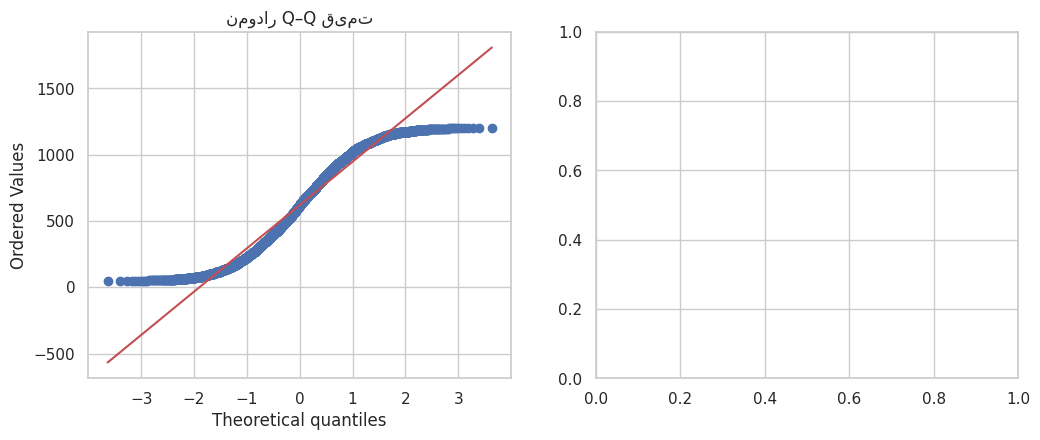

In [6]:
normal_sample = price_df["price"].dropna()
if len(normal_sample) > 5000:
    normal_sample = normal_sample.sample(5000, random_state=42)

normal_stat, normal_p = stats.normaltest(normal_sample)
print(f"حجم نمونه آزمون: {len(normal_sample):,}")
print(f"آماره آزمون D’Agostino: {normal_stat:.3f}")
print(f"p-value: {normal_p:.6g}")
print("نتیجه با سطح معناداری 0.05:", "رد فرض نرمال بودن" if normal_p < 0.05 else "شواهد کافی برای رد فرض نرمال بودن نداریم")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(normal_sample, dist="norm", plot=axes[0])
axes[0].set_title("نمودار Q–Q قیمت")
sns.histplot(normal_sample, bins=40, kde=True, ax=axes[1])
axes[1].set_title("توزیع نمونه قیمت")
plt.tight_layout()
plt.show()

**تفسیر آماری:** مقدار `p-value` کوچک‌تر از ۰٫۰۵ با رد فرض نرمال بودن سازگار است، اما به‌تنهایی اندازه انحراف یا اهمیت عملی آن را نمی‌گوید. برای قیمت‌های چوله و مقایسه چند گروه مستقل، آزمون‌های ناپارامتری می‌توانند انتخاب مناسبی باشند.

## ۶. همبستگی و رابطه بین متغیرهای عددی

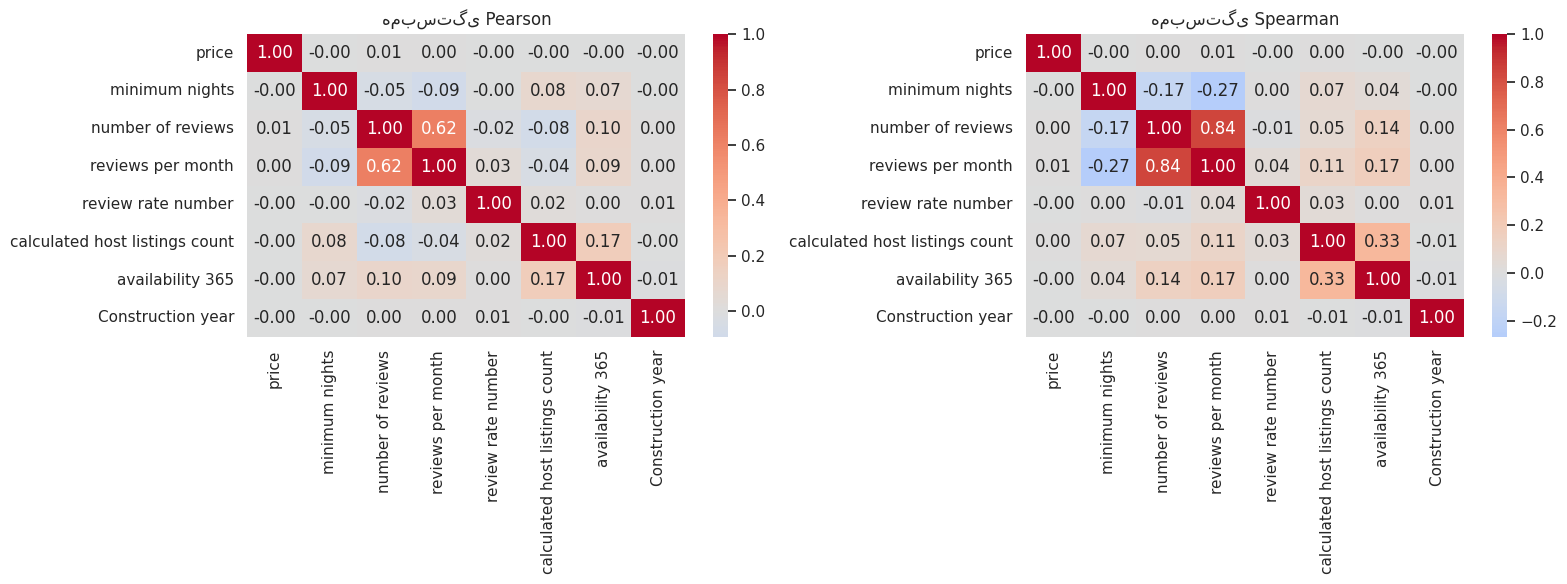

,price,minimum nights,number of reviews,reviews per month,review rate number,calculated host listings count,availability 365,Construction year
price,1.000,-0.003,0.005,0.005,-0.005,-0.000,-0.002,-0.004
minimum nights,-0.003,1.000,-0.050,-0.093,-0.003,0.085,0.070,-0.001
number of reviews,0.005,-0.050,1.000,0.618,-0.018,-0.081,0.100,0.002
reviews per month,0.005,-0.093,0.618,1.000,0.033,-0.040,0.092,0.004
review rate number,-0.005,-0.003,-0.018,0.033,1.000,0.024,0.004,0.005
calculated host listings count,-0.000,0.085,-0.081,-0.040,0.024,1.000,0.175,-0.003
availability 365,-0.002,0.070,0.100,0.092,0.004,0.175,1.000,-0.008
Construction year,-0.004,-0.001,0.002,0.004,0.005,-0.003,-0.008,1.000


In [7]:
corr_cols = [c for c in [
    "price", "minimum nights", "number of reviews", "reviews per month",
    "review rate number", "calculated host listings count", "availability 365",
    "Construction year"
] if c in price_df.columns]
corr_data = price_df[corr_cols].copy()
pearson_corr = corr_data.corr(method="pearson", numeric_only=True)
spearman_corr = corr_data.corr(method="spearman", numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("همبستگی Pearson")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("همبستگی Spearman")
plt.tight_layout()
plt.show()

display(pearson_corr.round(3))

Pearson رابطه خطی را اندازه می‌گیرد و به نقاط پرت حساس‌تر است؛ Spearman رابطه یکنواخت رتبه‌ای را می‌سنجد و در برابر برخی انحراف‌ها مقاوم‌تر است. همبستگی ضعیف به معنی نبود هر نوع رابطه نیست؛ ممکن است رابطه غیرخطی باشد یا عوامل دیگری در آن دخیل باشند.

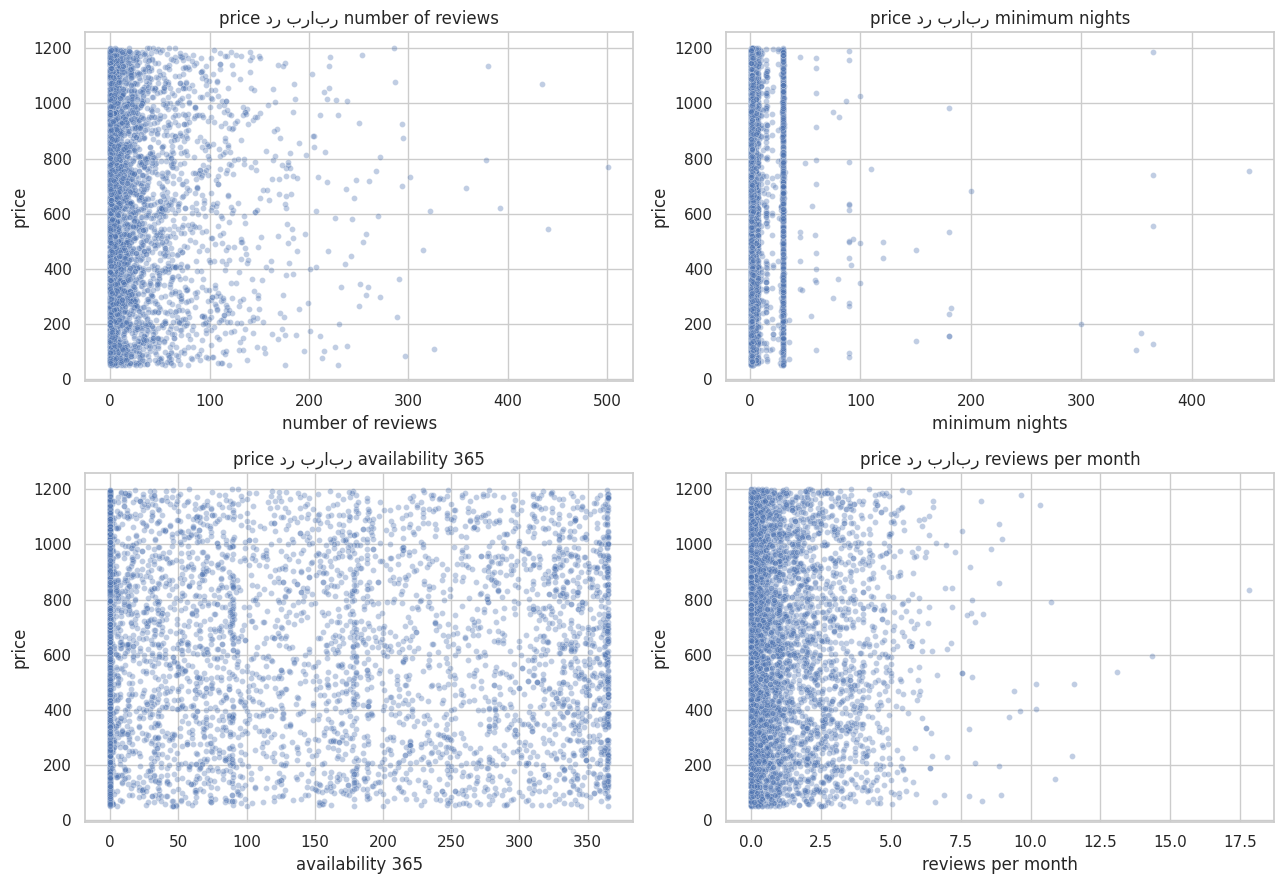

In [8]:
scatter_pairs = [
    ("number of reviews", "price"),
    ("minimum nights", "price"),
    ("availability 365", "price"),
    ("reviews per month", "price")
]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (x, y) in zip(axes.flat, scatter_pairs):
    subset = price_df[[x, y]].dropna()
    if len(subset) > 5000:
        subset = subset.sample(5000, random_state=42)
    sns.scatterplot(data=subset, x=x, y=y, alpha=0.35, s=18, ax=ax)
    ax.set_title(f"{y} در برابر {x}")
plt.tight_layout()
plt.show()

## ۷. آزمون فرضیه اول: آیا قیمت بین انواع اتاق تفاوت دارد؟

**فرض صفر:** توزیع قیمت در گروه‌های نوع اتاق یکسان است.  
**فرض مقابل:** حداقل یکی از گروه‌ها با گروه دیگر تفاوت دارد.  
از Kruskal–Wallis استفاده می‌کنیم، چون قیمت‌ها ممکن است چوله باشند. گروه‌هایی با تعداد بسیار کم نیز در خروجی مشخص می‌شوند.

In [9]:
room_groups = []
room_group_names = []
for name, group in price_df.groupby("room type"):
    values = group["price"].dropna().to_numpy()
    if len(values) >= 2:
        room_groups.append(values)
        room_group_names.append(name)

if len(room_groups) >= 2:
    kw_stat, kw_p = stats.kruskal(*room_groups)
    n_total = sum(len(g) for g in room_groups)
    k = len(room_groups)
    # اندازه اثر epsilon-squared تقریبی برای Kruskal-Wallis
    epsilon_sq = max(0, (kw_stat - k + 1) / (n_total - k)) if n_total > k else np.nan
    print("گروه‌ها:", {name: len(vals) for name, vals in zip(room_group_names, room_groups)})
    print(f"Kruskal-Wallis H = {kw_stat:.3f}")
    print(f"p-value = {kw_p:.6g}")
    print(f"اندازه اثر epsilon-squared ≈ {epsilon_sq:.4f}")
    print("نتیجه:", "تفاوت آماری معنادار مشاهده شد" if kw_p < 0.05 else "شواهد کافی برای تفاوت آماری نداریم")
else:
    print("برای آزمون، تعداد گروه کافی با داده معتبر وجود ندارد.")

گروه‌ها: {'Entire home/apt': 53296, 'Hotel room': 115, 'Private room': 46200, 'Shared room': 2200}
Kruskal-Wallis H = 3.649
p-value = 0.301987
اندازه اثر epsilon-squared ≈ 0.0000
نتیجه: شواهد کافی برای تفاوت آماری نداریم


اگر آزمون کلی معنادار شود، فقط می‌توان گفت حداقل یک گروه با گروه دیگر فرق دارد؛ آزمون کلی مشخص نمی‌کند کدام جفت گروه‌ها متفاوت‌اند. برای آن، آزمون‌های زوجی پس از آزمون کلی و اصلاح چندگانه‌بودن (مثلاً Holm) لازم است. تفاوت آماری همچنین به‌تنهایی علت تفاوت قیمت را مشخص نمی‌کند.

## ۸. آزمون فرضیه دوم: ارتباط قیمت و تعداد نظرات

**فرض صفر:** همبستگی رتبه‌ای جامعه بین قیمت و تعداد نظرات صفر است.  
**فرض مقابل:** همبستگی رتبه‌ای جامعه صفر نیست.  
استفاده از Spearman برای داده‌هایی که چولگی یا نقاط پرت دارند، اغلب معقول‌تر از اتکا به Pearson است.

In [10]:
review_pair = price_df[["price", "number of reviews"]].dropna()
rho, rho_p = stats.spearmanr(review_pair["price"], review_pair["number of reviews"])
print(f"تعداد مشاهدات: {len(review_pair):,}")
print(f"Spearman rho = {rho:.4f}")
print(f"p-value = {rho_p:.6g}")
print("نتیجه:", "شواهدی از همبستگی رتبه‌ای معنادار وجود دارد" if rho_p < 0.05 else "شواهد کافی برای همبستگی رتبه‌ای وجود ندارد")
print("شدت رابطه بر اساس قدرمطلق rho:", 
      "ضعیف" if abs(rho) < 0.3 else ("متوسط" if abs(rho) < 0.7 else "قوی"))

تعداد مشاهدات: 101,628
Spearman rho = 0.0044
p-value = 0.157466
نتیجه: شواهد کافی برای همبستگی رتبه‌ای وجود ندارد
شدت رابطه بر اساس قدرمطلق rho: ضعیف


## ۹. آزمون فرضیه سوم: ارتباط نوع اتاق و امکان رزرو فوری

برای دو متغیر دسته‌ای `room type` و `instant_bookable` از آزمون کای‌دو استقلال استفاده می‌کنیم. فرض صفر می‌گوید این دو متغیر مستقل‌اند. اندازه اثر Cramér’s V نیز کنار p-value گزارش می‌شود تا فقط به معناداری آماری تکیه نکنیم.

In [11]:
from scipy.stats import chi2_contingency

if {"room type", "instant_bookable"}.issubset(df.columns):
    cat = df[["room type", "instant_bookable"]].dropna()
    contingency = pd.crosstab(cat["room type"], cat["instant_bookable"])
    display(contingency)
    chi2, chi_p, dof, expected = chi2_contingency(contingency)
    n = contingency.to_numpy().sum()
    r, c = contingency.shape
    denom = n * min(r - 1, c - 1)
    cramers_v = np.sqrt(chi2 / denom) if denom > 0 else np.nan
    print(f"Chi-square = {chi2:.3f}, df = {dof}, p-value = {chi_p:.6g}")
    print(f"Cramér's V = {cramers_v:.4f}")
    print("نتیجه:", "شواهدی از وابستگی آماری وجود دارد" if chi_p < 0.05 else "شواهد کافی برای وابستگی آماری نداریم")
else:
    print("ستون‌های مورد نیاز برای آزمون کای‌دو در داده موجود نیستند.")

instant_bookable,False,True
room type,,
Entire home/apt,26787,26579
Hotel room,53,62
Private room,23276,22991
Shared room,1070,1135


Chi-square = 3.465, df = 3, p-value = 0.325356
Cramér's V = 0.0058
نتیجه: شواهد کافی برای وابستگی آماری نداریم


## ۱۰. تحلیل منطقه‌ای و خلاصه یافته‌های عددی

In [12]:
# جدول خلاصه قیمت بر اساس منطقه
if "neighbourhood group" in price_df.columns:
    area_summary = price_df.groupby("neighbourhood group")["price"].agg(
        n="count", mean="mean", median="median", std="std"
    ).sort_values("median", ascending=False)
    display(area_summary.round(2))

# ارتباط قیمت و متغیرهای عددی با Spearman
corr_results = []
for col in ["minimum nights", "number of reviews", "reviews per month",
            "review rate number", "calculated host listings count", "availability 365"]:
    if col in price_df.columns:
        pair = price_df[["price", col]].dropna()
        if len(pair) >= 3:
            r, p = stats.spearmanr(pair["price"], pair[col])
            corr_results.append({"variable": col, "n": len(pair), "spearman_rho": r, "p_value": p})
corr_results = pd.DataFrame(corr_results)
if not corr_results.empty:
    corr_results["abs_rho"] = corr_results["spearman_rho"].abs()
    display(corr_results.sort_values("abs_rho", ascending=False).drop(columns="abs_rho").round(5))

,n,mean,median,std
neighbourhood group,,,,
Bronx,2687,627.76,632.0,323.81
Staten Island,946,623.99,628.0,325.78
Queens,13164,630.22,628.0,334.15
Brooklyn,41538,626.50,626.0,331.94
Manhattan,43448,622.65,621.0,331.26


,variable,n,spearman_rho,p_value
2,reviews per month,101667,0.00544,0.08309
3,review rate number,101492,-0.00474,0.13113
1,number of reviews,101628,0.00443,0.15747
0,minimum nights,101398,-0.00399,0.20422
5,availability 365,98190,-0.00235,0.46198
4,calculated host listings count,101492,0.00120,0.70275


## ۱۱. نتیجه‌گیری خودکار بر اساس داده‌های واقعی

سلول زیر مهم‌ترین اعداد را از داده استخراج می‌کند تا هنگام اجرای مجدد نوت‌بوک، نتیجه‌ها به‌روز باشند. متن نهایی باید همراه با نمودارها خوانده شود و از نتیجه‌گیری علّی پرهیز کند.

In [13]:
median_price = price_df["price"].median()
mean_price = price_df["price"].mean()
skew_price = price_df["price"].skew()
print(f"تعداد آگهی‌های قابل استفاده در تحلیل قیمت: {len(price_df):,}")
print(f"میانه قیمت: ${median_price:,.2f}")
print(f"میانگین قیمت: ${mean_price:,.2f}")
print(f"چولگی قیمت: {skew_price:.3f}")

if "room type" in price_df.columns:
    top_room = price_df.groupby("room type")["price"].median().sort_values(ascending=False)
    print(f"بالاترین میانه قیمت بین انواع اتاق: {top_room.index[0]} (${top_room.iloc[0]:,.2f})")
    print(f"پایین‌ترین میانه قیمت بین انواع اتاق: {top_room.index[-1]} (${top_room.iloc[-1]:,.2f})")

if "neighbourhood group" in price_df.columns:
    top_area = price_df.groupby("neighbourhood group")["price"].median().sort_values(ascending=False)
    print(f"بالاترین میانه قیمت منطقه‌ای: {top_area.index[0]} (${top_area.iloc[0]:,.2f})")
    print(f"پایین‌ترین میانه قیمت منطقه‌ای: {top_area.index[-1]} (${top_area.iloc[-1]:,.2f})")

print("\nیادآوری:")
print("- تفاوت‌ها توصیفی/آماری‌اند و به‌تنهایی علت قیمت را اثبات نمی‌کنند.")
print("- کیفیت داده و مقدارهای غیرعادی می‌توانند روی برآوردها اثر بگذارند.")
print("- برای تصمیم‌گیری قوی‌تر، تحلیل حساسیت با و بدون مقادیر پرت را مقایسه کنید.")

تعداد آگهی‌های قابل استفاده در تحلیل قیمت: 101,811
میانه قیمت: $625.00
میانگین قیمت: $625.36
چولگی قیمت: 0.001
بالاترین میانه قیمت بین انواع اتاق: Shared room ($651.50)
پایین‌ترین میانه قیمت بین انواع اتاق: Private room ($623.00)
بالاترین میانه قیمت منطقه‌ای: Bronx ($632.00)
پایین‌ترین میانه قیمت منطقه‌ای: Manhattan ($621.00)

یادآوری:
- تفاوت‌ها توصیفی/آماری‌اند و به‌تنهایی علت قیمت را اثبات نمی‌کنند.
- کیفیت داده و مقدارهای غیرعادی می‌توانند روی برآوردها اثر بگذارند.
- برای تصمیم‌گیری قوی‌تر، تحلیل حساسیت با و بدون مقادیر پرت را مقایسه کنید.


## ۱۲. محدودیت‌ها و پیشنهادهای ادامه کار

1. دیتاست ممکن است شامل خطاهای ثبت، مقادیر نامعتبر یا داده‌های ناقص باشد.
2. قیمت مشاهده‌شده لزوماً قیمت نهایی پرداخت‌شده توسط مهمان نیست و هزینه‌های جانبی ممکن است جدا باشند.
3. تعداد نظرها الزاماً شاخص کیفیت نیست؛ به زمان حضور آگهی، نرخ رزرو و رفتار مهمانان هم وابسته است.
4. گروه‌های بسیار کوچک (مانند برخی انواع اتاق) ممکن است برآوردهای ناپایدار داشته باشند.
5. آزمون‌های متعدد احتمال خطای نوع اول را افزایش می‌دهند؛ برای تحلیل‌های زوجی باید اصلاح چندگانه‌بودن انجام شود.
6. این تحلیل توصیفی است؛ برای پیش‌بینی قیمت باید داده‌ها، ویژگی‌ها و ارزیابی مدل جداگانه طراحی شوند.

### جمع‌بندی
این پروژه مسیر کامل EDA را طی می‌کند: استخراج و بررسی کیفیت داده، پاک‌سازی مستند، آمار توصیفی، نمودارهای تک‌متغیره و چندمتغیره، بررسی توزیع، همبستگی و آزمون فرضیه‌ها. نتیجه نهایی باید بر مبنای خروجی سلول‌ها و با ذکر محدودیت‌های داده ارائه شود.